# Data Cleaning Challenge

In [1]:
import pandas as pd
import datetime as dt

In [2]:
datos = pd.read_csv('data.csv')
datos.head()

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
0,2017,Fall,30406,596,4991,328
1,2017,Summer,8385,150,3195,330
2,2017,Spring,28334,586,4883,305
3,2016,Fall,30671,586,5096,307
4,2016,Simmer,8107,154,3370,306


In [3]:
datos.shape
datos.size
datos.info()
datos.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Year      58 non-null     int64 
 1   Semester  58 non-null     object
 2   Ungrad    58 non-null     int64 
 3   Prof      58 non-null     int64 
 4   Grad      58 non-null     int64 
 5   Post-Doc  58 non-null     int64 
dtypes: int64(5), object(1)
memory usage: 2.8+ KB


,Year,Ungrad,Prof,Grad,Post-Doc
count,58.000000,58.000000,58.000000,58.000000,58.000000
mean,2007.827586,18137.931034,307.672414,4277.034483,100.051724
std,5.632418,8757.532503,239.326129,1620.131367,144.848066
min,1998.000000,5712.000000,0.000000,2858.000000,0.000000
25%,2003.000000,7668.000000,102.500000,3198.250000,0.000000
50%,2008.000000,20810.500000,401.500000,4416.500000,0.000000
75%,2012.750000,23325.250000,578.250000,4676.750000,292.000000
max,2017.000000,41033.000000,596.000000,15096.000000,330.000000


In [4]:
datos[datos['Year'].isin([2014, 2015, 2016])]

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
3,2016,Fall,30671,586,5096,307
4,2016,Simmer,8107,154,3370,306
5,2016,Spring,27868,583,4909,299
6,2015,Falll,30034,584,15096,287
7,2015,Summer,7866,159,3305,310
8,2015,Sprig,27021,593,4851,329
9,2014,Fall,28893,592,4950,297
10,2014,Summer,7839,173,3208,310
11,2014,Spring,25751,586,4638,321


In [5]:
datos['Semester'].value_counts().sort_index()

Semester
Fall      19
Falll      1
Simmer     4
Sprig      2
Spring    17
Summer    15
Name: count, dtype: int64

In [6]:
datos[datos['Semester'].isin(['Simmer', 'Falll', 'Sprig'])]

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
4,2016,Simmer,8107,154,3370,306
6,2015,Falll,30034,584,15096,287
8,2015,Sprig,27021,593,4851,329
20,2011,Sprig,21395,583,4804,0
25,2009,Simmer,5859,140,3120,0
46,2002,Simmer,7075,0,2932,0
55,1999,Simmer,6033,0,2858,0


In [7]:
datos['Semester'] = datos['Semester'].replace({'Simmer':'Summer', 'Falll':'Fall', 'Sprig':'Spring'})

In [8]:
datos['Semester'].value_counts()

Semester
Fall      20
Summer    19
Spring    19
Name: count, dtype: int64

In [9]:
datos.shape

(58, 6)

In [10]:
datos['Semester'].value_counts().sum()

np.int64(58)

In [11]:
datos.duplicated().sum()

np.int64(0)

In [12]:
datos[datos.duplicated(keep=False)]

,Year,Semester,Ungrad,Prof,Grad,Post-Doc


In [13]:
datos.duplicated(subset=["Year", "Semester"]).sum()

np.int64(0)

In [14]:
datos.isnull().sum().sum()

np.int64(0)

In [15]:
datos.sort_values(['Grad'], ascending= False).head(5)

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
6,2015,Fall,30034,584,15096,287
3,2016,Fall,30671,586,5096,307
0,2017,Fall,30406,596,4991,328
21,2010,Fall,23104,587,4991,0
9,2014,Fall,28893,592,4950,297


In [16]:
datos[datos['Semester'] == 'Fall'][['Year', 'Grad']].sort_values('Year')

,Year,Grad
57,1998,4158
54,1999,4209
51,2000,4364
48,2001,4364
45,2002,4499
42,2003,4741
39,2004,4618
36,2005,4578
33,2006,4583
30,2007,4664


In [17]:
datos[datos['Grad'] > 5000][['Year', 'Semester']].sort_values(['Year'])

,Year,Semester
6,2015,Fall
3,2016,Fall


In [18]:
datos['Grad'].mean()

np.float64(4277.0344827586205)

In [19]:
datos[datos["Year"] == 2015]

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
6,2015,Fall,30034,584,15096,287
7,2015,Summer,7866,159,3305,310
8,2015,Spring,27021,593,4851,329


In [20]:
datos[datos["Semester"] == "Fall"][["Year", "Grad"]].sort_values("Year")

,Year,Grad
57,1998,4158
54,1999,4209
51,2000,4364
48,2001,4364
45,2002,4499
42,2003,4741
39,2004,4618
36,2005,4578
33,2006,4583
30,2007,4664


In [21]:
datos.dtypes

Year         int64
Semester    object
Ungrad       int64
Prof         int64
Grad         int64
Post-Doc     int64
dtype: object

In [22]:
datos[["Ungrad", "Prof", "Grad", "Post-Doc"]].lt(0).sum()

Ungrad      0
Prof        0
Grad        0
Post-Doc    0
dtype: int64

In [23]:
datos[["Ungrad", "Prof", "Grad", "Post-Doc"]].eq(0).sum()

Ungrad       0
Prof        14
Grad         0
Post-Doc    39
dtype: int64

In [24]:
datos['Prof'].value_counts()

Prof
0      14
586     5
583     2
119     2
587     2
588     2
596     1
431     1
492     1
437     1
439     1
432     1
116     1
124     1
406     1
408     1
98      1
403     1
409     1
487     1
140     1
531     1
526     1
150     1
564     1
561     1
189     1
212     1
188     1
167     1
173     1
592     1
593     1
159     1
584     1
154     1
400     1
Name: count, dtype: int64

In [25]:
datos['Post-Doc'].value_counts()

Post-Doc
0      39
310     3
292     2
297     1
276     1
302     1
316     1
286     1
321     1
328     1
330     1
287     1
299     1
306     1
307     1
305     1
329     1
Name: count, dtype: int64

In [28]:
datos.sort_values(['Grad'], ascending= False).head(5)

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
6,2015,Fall,30034,584,15096,287
3,2016,Fall,30671,586,5096,307
0,2017,Fall,30406,596,4991,328
21,2010,Fall,23104,587,4991,0
9,2014,Fall,28893,592,4950,297


In [29]:
datos.groupby('Semester')['Ungrad'].mean().sort_values(ascending= False)

Semester
Fall      24160.950000
Spring    23110.947368
Summer     6824.894737
Name: Ungrad, dtype: float64

In [30]:
datos.groupby('Semester')['Grad'].mean().sort_values(ascending= False)

Semester
Fall      5173.900000
Spring    4505.526316
Summer    3104.473684
Name: Grad, dtype: float64

In [31]:
datos.groupby('Semester')['Post-Doc'].mean().sort_values(ascending= False)

Semester
Fall      103.650000
Summer     98.315789
Spring     98.000000
Name: Post-Doc, dtype: float64

In [32]:
datos.groupby(['Year', 'Semester'])['Ungrad'].mean().reset_index()

,Year,Semester,Ungrad
0,1998,Fall,21427.0
1,1999,Fall,21901.0
2,1999,Spring,19825.0
3,1999,Summer,6033.0
4,2000,Fall,22481.0
5,2000,Spring,20251.0
6,2000,Summer,6198.0
7,2001,Fall,23460.0
8,2001,Spring,20889.0
9,2001,Summer,6815.0


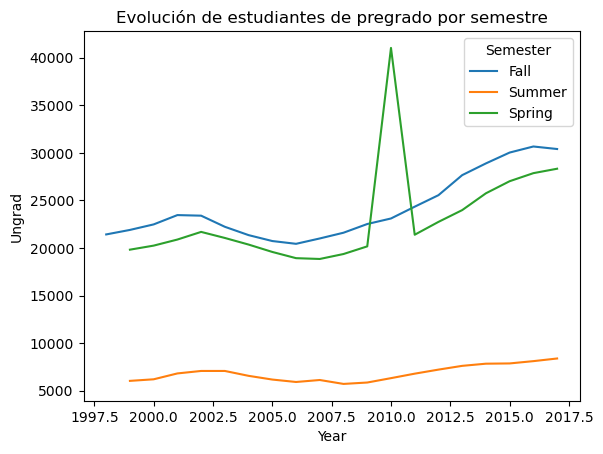

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(
    data=datos,
    x='Year',
    y='Ungrad',
    hue='Semester'
)

plt.title('Evolución de estudiantes de pregrado por semestre')
plt.show()

In [34]:
datos[datos['Semester'] == 'Spring'].sort_values('Ungrad')

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
32,2007,Spring,18847,437,4426,0
35,2006,Spring,18932,432,4345,0
29,2008,Spring,19368,487,4590,0
38,2005,Spring,19585,406,4435,0
56,1999,Spring,19825,0,4048,0
26,2009,Spring,20172,526,4614,0
53,2000,Spring,20251,0,4082,0
41,2004,Spring,20361,403,4518,0
50,2001,Spring,20889,0,4199,0
44,2003,Spring,21056,400,4407,0


In [35]:
datos[datos['Semester'] == 'Spring'].sort_values('Ungrad', ascending=False)

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
23,2010,Spring,41033,561,4689,0
2,2017,Spring,28334,586,4883,305
5,2016,Spring,27868,583,4909,299
8,2015,Spring,27021,593,4851,329
11,2014,Spring,25751,586,4638,321
14,2013,Spring,23983,586,4529,316
17,2012,Spring,22744,588,4456,292
47,2002,Spring,21693,0,4182,0
20,2011,Spring,21395,583,4804,0
44,2003,Spring,21056,400,4407,0


In [38]:
datos[datos['Year'] == 2010]

,Year,Semester,Ungrad,Prof,Grad,Post-Doc
21,2010,Fall,23104,587,4991,0
22,2010,Summer,6319,189,3126,0
23,2010,Spring,41033,561,4689,0


In [39]:
datos[datos['Year'] == 2010][['Year', 'Ungrad']].sort_values('Ungrad', ascending= False)

,Year,Ungrad
23,2010,41033
21,2010,23104
22,2010,6319


In [42]:
spring = datos[datos['Semester'] == 'Spring'].describe()
spring

,Year,Ungrad,Prof,Grad,Post-Doc
count,19.000000,19.000000,19.000000,19.000000,19.000000
mean,2008.000000,23110.947368,408.263158,4505.526316,98.000000
std,5.627314,5300.112174,227.774948,260.458649,148.389877
min,1999.000000,18847.000000,0.000000,4048.000000,0.000000
25%,2003.500000,19998.500000,401.500000,4376.000000,0.000000
50%,2008.000000,21056.000000,487.000000,4518.000000,0.000000
75%,2012.500000,24867.000000,584.500000,4663.500000,295.500000
max,2017.000000,41033.000000,593.000000,4909.000000,329.000000


In [46]:
spring = datos[datos['Semester'] == 'Spring']
media_original = spring['Ungrad'].mean()
media_sin_outlier = spring.loc[spring['Year'] != 2010, 'Ungrad'].mean()

print(media_original)
print(media_sin_outlier)

23110.947368421053
22115.277777777777


In [47]:
spring['Ungrad'].agg(['mean', 'median', 'std'])

mean      23110.947368
median    21056.000000
std        5300.112174
Name: Ungrad, dtype: float64

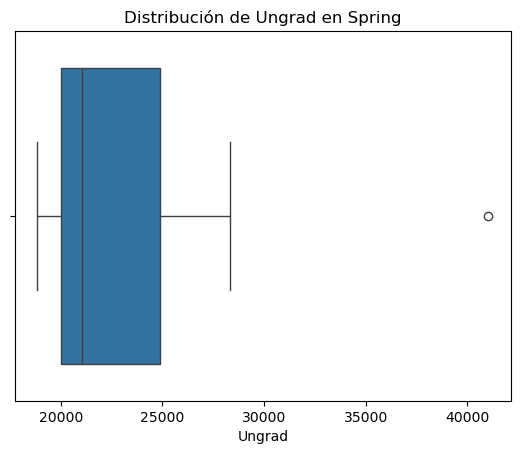

In [48]:
sns.boxplot(data=spring, x='Ungrad')
plt.title('Distribución de Ungrad en Spring')
plt.show()